## Module 3: Computational Drug Discovery Project 


## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 
Provide a brief (<200 word) background of obesity, available treatments, and especially why improved treatments are needed. Your answers may include for example: 
Prevalence & incidence, Symptoms, Diagnosis, Standard of care treatments (& reimbursement), Disease progression & prognosis, Biological mechanisms (anatomy, organ physiology, cell & molecular physiology), Clinical Trials/next-gen therapies.

Please provide citations and/or hyperlinks to where you obtained information (including AI) for each of the bullet points.

## Task 1: Fit a receptor binding model for Cavalitide:

Our first task aims to identify how Cavalitide, a novel GLP-1 agonist, binds to GLP1 receptors in the body. In this section we will develop a pharmacodynamic model of how GLP1, Semaglutide, and Cavalitide can each bind and activate the GLP1 recepter. First, we will plot Cavalitide binding data and find a curve of best fit using the curve_fit function on Fact vs. concentration of Cavalitide to determine the fitted dissociation constant for Cavalitide. Semaglutide will be modeled to show how it maintains GLP-1R activation even at fasted periods, which increases satiety and is the main driver of weight loss in users. Lastly, our third model will compare the behavior and Kd values of Cavalitide and Semaglutide to GLP-1 receptors as the concentration of the drug increases. 

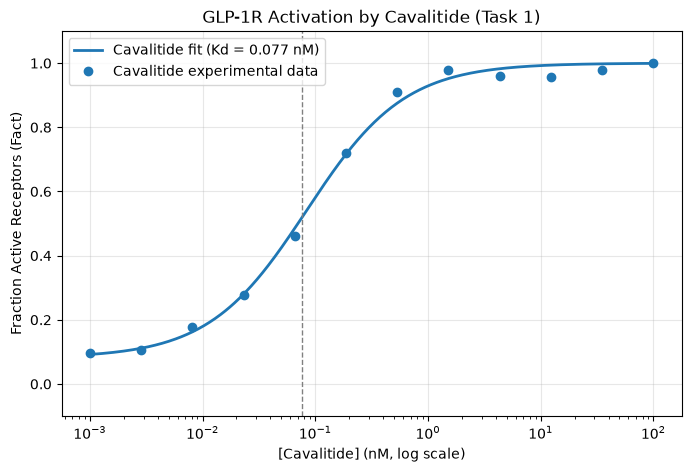

Fitted Cavalitide Kd = 0.0770 nM


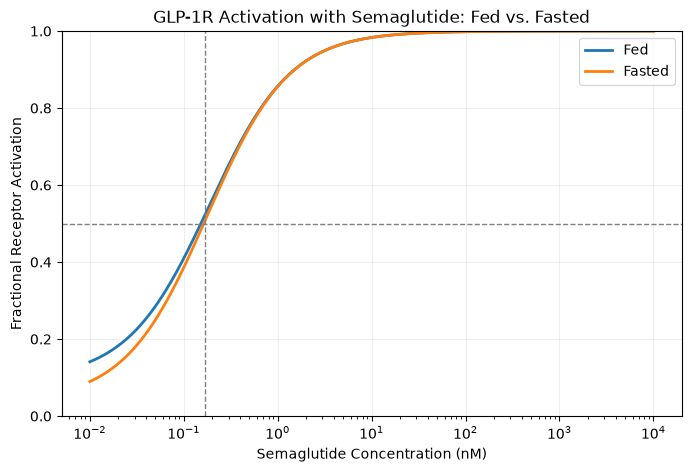

Semaglutide Kd = 0.38 nM


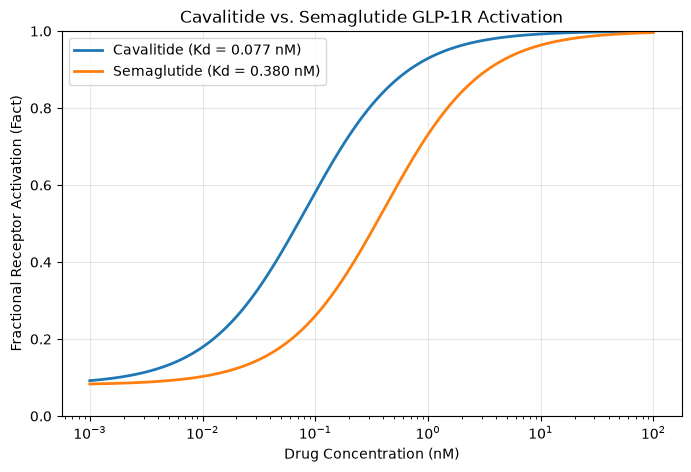

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

Kd1 = 0.17 # GLP1 Kd [nM]
L1 = 0.015 # Fasting GLP1 [nM]
L = np.logspace(-3, 2, 500)

# Load Cavalitide binding data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L_data, Fact_data = data[:, 0], data[:, 1]

# Curve fit to find Kd2 for Cavalitide
popt, _ = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2), L_data, Fact_data, p0=[0.1], bounds=(0, np.inf))
Kd2_cav = popt[0]

#Plotting Cavalitide Concentration vs. Fraction Active Receptors (Fact)
plt.figure(figsize=(8, 5))
line, = plt.semilogx(L, Fact(L1, L, Kd1, Kd2_cav), lw=2, label=f"Cavalitide fit (Kd = {Kd2_cav:.3f} nM)")
plt.semilogx(L_data, Fact_data, "o", c=line.get_color(), label="Cavalitide experimental data")
plt.axvline(Kd2_cav, ls="--", color="gray", lw=1)
plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM, log scale)")
plt.ylabel("Fraction Active Receptors (Fact)")
plt.title("GLP-1R Activation by Cavalitide (Task 1)")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()
print(f"Fitted Cavalitide Kd = {Kd2_cav:.4f} nM")

#Creating a Function to calculate fractional receptor activation for fed vs. fasted states with semaglutide competition
def Fact(G, S, kd_1, kd_2):
    """Fractional receptor activation: (kd_2*G + kd_1*S) / (kd_1*kd_2 + kd_2*G + kd_1*S)"""
    return (kd_2 * G + kd_1 * S) / (kd_1 * kd_2 + kd_2 * G + kd_1 * S) 

kd_1 = 0.38                      # Semaglutide dissociation constant [nM]
kd_2 = 0.17                     # GLP1 dissociation constant [nM]   
G_fed = 0.040                # GLP1 (fed) concentration [nM]
G_fasted = 0.015             # GLP1 (fasted) concentration [nM]
S = np.logspace(-2, 4, 500)     # ligand concentration, 0.01 to 10,000 [nM]

#Calculating fractional receptor activation for fed vs. fasted states
Fact_fed = Fact(G_fed, S, kd_1, kd_2)
Fact_fasted = Fact(G_fasted, S, kd_1, kd_2)

#Plotting graph with two curves for fed and fasted states with semiglutide competition 
plt.figure(figsize=(8,5))
plt.semilogx(S, Fact_fed, label="Fed", lw=2)
plt.semilogx(S, Fact_fasted, label="Fasted", lw=2)
plt.axhline(0.5, ls="--", c="gray", lw=1)
plt.axvline(kd_2, ls="--", c="gray", lw=1)
plt.ylim(0,1)
plt.xlabel("Semaglutide Concentration (nM)")
plt.ylabel("Fractional Receptor Activation")
plt.title("GLP-1R Activation with Semaglutide: Fed vs. Fasted")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print(f"Semaglutide Kd = {kd_1} nM")

#Making a graph to compare cavalitide and semaglutide binding to GLP1R
# Calculate fractional receptor activation
Fact_cav = Fact(0.015, L, kd_2, Kd2_cav)
Fact_sema = Fact(0.015, L, kd_2, kd_1)

# Plot comparison
plt.figure(figsize=(8,5))
plt.semilogx(L, Fact_cav, lw=2,
             label=f"Cavalitide (Kd = {Kd2_cav:.3f} nM)")
plt.semilogx(L, Fact_sema, lw=2,
             label=f"Semaglutide (Kd = {kd_1:.3f} nM)")
plt.xlabel("Drug Concentration (nM)")
plt.ylabel("Fractional Receptor Activation (Fact)")
plt.title("Cavalitide vs. Semaglutide GLP-1R Activation")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Our pharmacodynamic model has identified the Kd for Cavalitide to be 0.077 nM, which is significantly lower than Semaglutide's Kd of 0.38 nM. Figure 3 compares the curves of Semaglutide and Cavalitide and their Fact percentages as concentration goes up. Cavalitide's lower Kd means it has a higher binding affinity to GLP1R, which allows it to achieve the same Fact at lower concentrations compared to Semaglutide. This means Cavalitide could be effective at lower doses, which would benefit the drug manufacturing industry since they would not have to produce as much, and could benefit patients as lower doses may prove to have less side effects. Cavalitide may also be able to better compete with endogenous GLP-1 and remain in the receptor for longer. 

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

To help design the Phase 1 clinical trial for the pill version of Cavalitide, we modeled the pharmacokinetics of similar GLP-1 agonists and Cavalitide. We reviewed and modeled the semaglutide pharmacokinetic model to simular Ozempic (weekly subcutaneous injection) and Wegovy (daily oral pill) and replaced Euler's method with scipy.integrate.solve_ivp to improve numerical accuracy. We then expanded the model to incorporate Cavalitide as a daily oral medication with an absorbption rate of ka = 0.006 1/h and plotted its predicted blood concentration over time. We ultimately optimized Cavalitide's dosing by changing the parameters to achieve a steady state free blood concentration of 0.5 nM. 

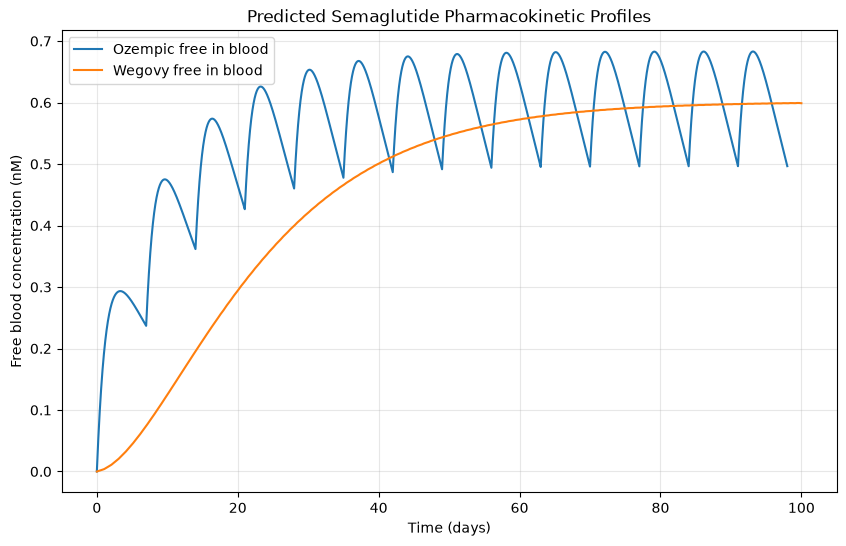

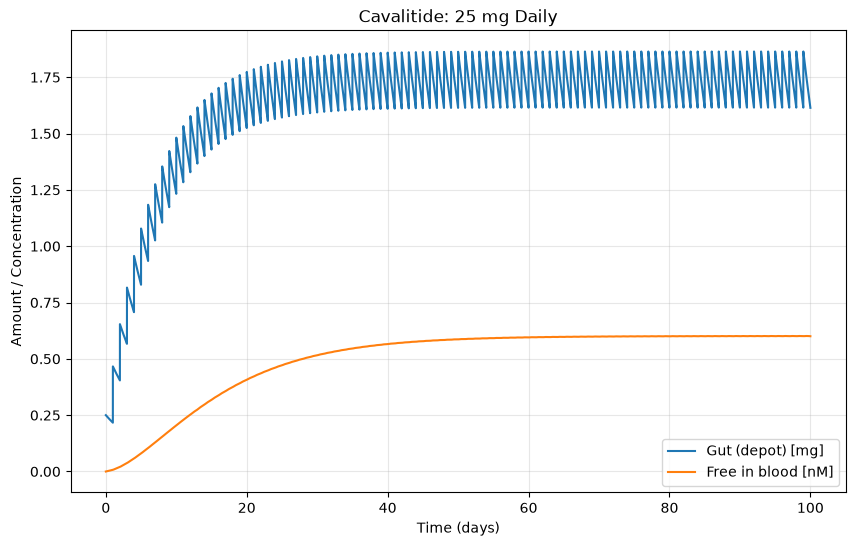

Optimal Cavalitide daily dose: 20.797068741271843 mg
Target free concentration: 0.5 nM


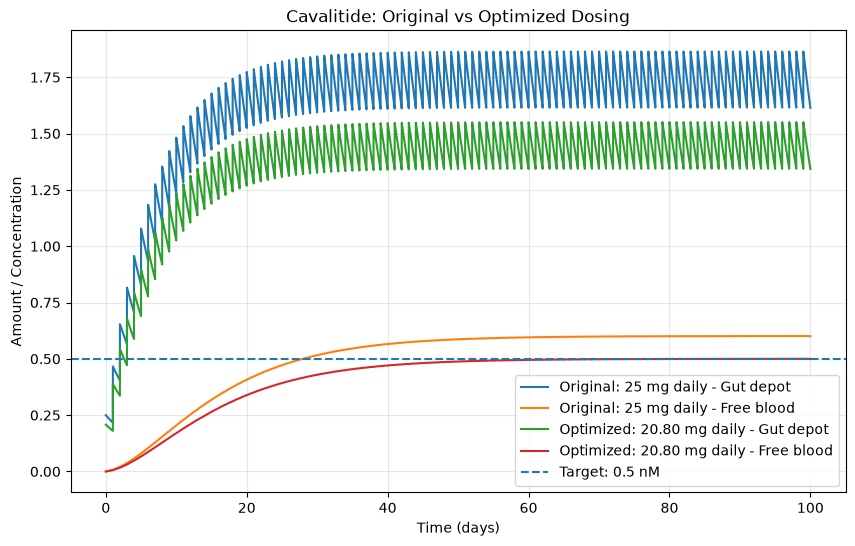

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

# SHARED PHARMACOKINETIC PARAMETERS
ke = 0.0039       # 1/h
V = 10.8          # L
MW = 4113.6       # g/mol
Ffree = 0.01      # Free fraction
dt = 0.1          # h

# DRUG PARAMETERS
products = {
    'Ozempic': dict(
        Favailable=0.89,
        ka=0.029,
        D=2.0,
        interval=168,
        n_doses=14,
        depot='Subcutaneous'
    ),

    'Wegovy': dict(
        Favailable=0.01,
        ka=0.0029,
        D=25.0,
        interval=24,
        n_doses=100,
        depot='Gut'
    ),

    'Cavalitide': dict(
        Favailable=0.01,
        ka=0.006,
        D=25.0,
        interval=24,
        n_doses=100,
        depot='Gut'
    )
}

# DIFFERENTIAL EQUATIONS
def ODEfunc(t, y):
    Asc, Cc = y

    dAsc = -ka_current * Asc
    dCc = ka_current * Asc / V - ke * Cc

    return [dAsc, dCc]

# SIMULATION USING solve_ivp
def simulate(drug, dose, n_doses=100):

    p = products[drug]

    Favailable = p['Favailable']
    ka = p['ka']
    interval = p['interval']

    global ka_current
    ka_current = ka

    y = np.array([0.0, 0.0])

    t_all = []
    Asc_all = []
    Cc_all = []

    for i in range(n_doses):

        # Add new oral/subcutaneous dose to depot
        y[0] += Favailable * dose

        t0 = i * interval
        t1 = (i + 1) * interval

        t_eval = np.linspace(t0, t1, int(interval/dt) + 1)

        sol = solve_ivp(
            ODEfunc,
            (t0, t1),
            y,
            t_eval=t_eval,
            method='RK45',
            rtol=1e-8,
            atol=1e-10
        )

        t_all.append(sol.t)
        Asc_all.append(sol.y[0])
        Cc_all.append(sol.y[1])

        y = sol.y[:, -1]

    t = np.concatenate(t_all)
    Asc = np.concatenate(Asc_all)
    Cc = np.concatenate(Cc_all)

    # Convert mg/L to nM
    Cc_nM = Cc * 1e6 / MW

    # Free drug concentration
    Cfree = Ffree * Cc_nM

    return t, Asc, Cfree

# PART A: OZEMPIC AND WEGOVY
plt.figure(figsize=(10, 6))

for drug in ['Ozempic', 'Wegovy']:

    p = products[drug]

    t, Asc, Cfree = simulate(
        drug,
        p['D'],
        p['n_doses']
    )

    plt.plot(
        t / 24,
        Cfree,
        label=f'{drug} free in blood'
    )

plt.xlabel('Time (days)')
plt.ylabel('Free blood concentration (nM)')
plt.title('Predicted Semaglutide Pharmacokinetic Profiles')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# PART B: CAVALITIDE AT 25 MG DAILY
t, Asc, Cfree = simulate(
    'Cavalitide',
    dose=25,
    n_doses=100
)

plt.figure(figsize=(10, 6))

plt.plot(
    t / 24,
    Asc,
    label='Gut (depot) [mg]'
)

plt.plot(
    t / 24,
    Cfree,
    label='Free in blood [nM]'
)

plt.xlabel('Time (days)')
plt.ylabel('Amount / Concentration')
plt.title('Cavalitide: 25 mg Daily')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# PART C: OPTIMIZE DAILY DOSE TO HIT 0.5 nM TARGET
target = 0.5

def objective(dose):

    t, Asc, Cfree = simulate(
        'Cavalitide',
        dose=dose,
        n_doses=100
    )

    # Average free concentration during final dosing interval
    final_interval = t >= (99 * 24)

    steady_state = np.mean(Cfree[final_interval])

    return (steady_state - target)**2


result = minimize_scalar(
    objective,
    bounds=(0.01, 100),
    method='bounded'
)

optimal_dose = result.x

print('Optimal Cavalitide daily dose:', optimal_dose, 'mg')
print('Target free concentration:', target, 'nM')


# COMPARE ORIGINAL AND OPTIMIZED DOSES
plt.figure(figsize=(10, 6))

for dose, label in [
    (25, 'Original: 25 mg daily'),
    (optimal_dose, f'Optimized: {optimal_dose:.2f} mg daily')
]:

    t, Asc, Cfree = simulate(
        'Cavalitide',
        dose=dose,
        n_doses=100
    )

    plt.plot(
        t / 24,
        Asc,
        label=f'{label} - Gut depot'
    )

    plt.plot(
        t / 24,
        Cfree,
        label=f'{label} - Free blood'
    )

plt.axhline(
    target,
    linestyle='--',
    label='Target: 0.5 nM'
)

plt.xlabel('Time (days)')
plt.ylabel('Amount / Concentration')
plt.title('Cavalitide: Original vs Optimized Dosing')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

The Phase 1 clinical trial was a success, and you achieved the desired 0.5 nM concentration of Cavalitide in your patients. Now it’s time to further customize the dosing for the Phase 2 clinical trial, where you’re more interested in efficacy. You’ll need to combine the PK model (Task 2) and PD model (Task 1) to predict how the fraction of activated receptors changes over time.

1. Embed the ligand-receptor model of Cavalitide (from Task 1, but just using your optimized Kd) into your cavalitidePK.py model. Let’s call this combined model cavalitidePKPD.py. Predict how the fraction of active GLP1R receptors changes over the first 100 days of treatment. 
2. Further optimize your dosing strategy so that you achieve close to 90% active GLP1 receptors at steady state (around 100 days).  Which dosing parameters did you adjust? Provide an interpretation of the clinical benefits of this adjustment.


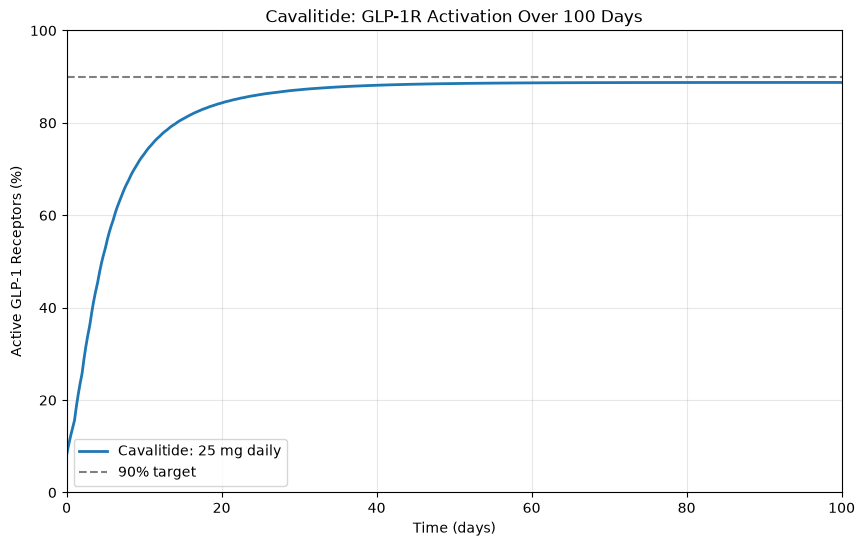


========== CAVALITIDE PK/PD RESULTS ==========
Original daily dose: 25.00 mg
Optimized daily dose: 28.542 mg
Average receptor activation at day 100: 90.00%
Average free Cavalitide concentration: 0.6862 nM
Peak receptor activation at day 100: 90.01%
Trough receptor activation at day 100: 89.99%


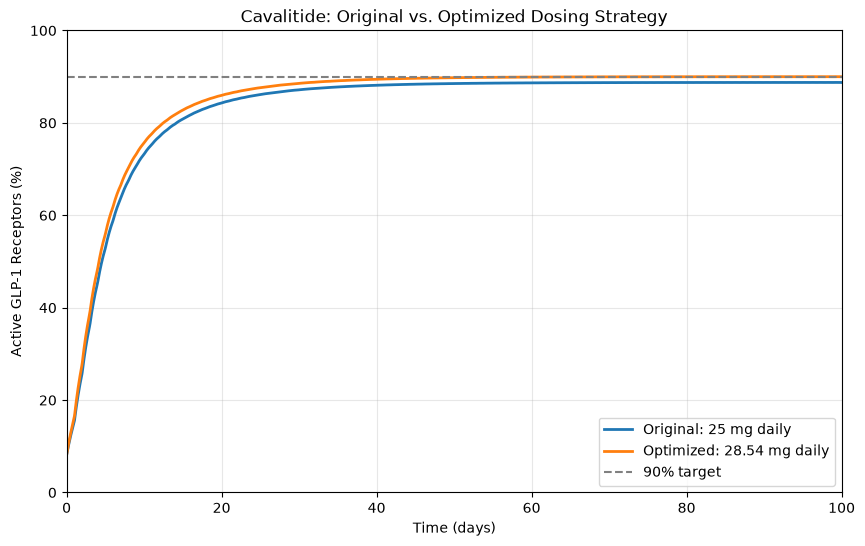

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

# 1. PHARMACOKINETIC PARAMETERS
Favailable = 0.01
ka = 0.006           # Cavalitide absorption rate (1/h)
ke = 0.0039          # Elimination rate (1/h)
V = 10.8             # Volume of distribution (L)
MW = 4113.6          # Molecular weight (g/mol)
Ffree = 0.01         # Free fraction
interval = 24        # Daily dosing (hours)
n_doses = 100        # 100 days
dt = 0.1             # Time resolution (hours)
initial_dose = 25    # Initial Cavalitide dose (mg)

# 2. PHARMACODYNAMIC PARAMETERS
Kd_GLP1 = 0.17       # GLP-1 dissociation constant (nM)
Kd_Cav = 0.077       # Cavalitide optimized Kd (nM)
L1 = 0.015           # Endogenous GLP-1 (fasted) [nM]
target_activation = 0.90


# 3. PHARMACOKINETIC DIFFERENTIAL EQUATIONS
def ODEfunc(t, y, ka, Favailable):

    Agut, Cc = y

    dAgut = -ka * Agut

    dCc = (Favailable * ka * Agut / V) - ke * Cc

    return [dAgut, dCc]

# 4. SIMULATE REPEATED DAILY DOSING
def simulate(dose):

    y = np.array([0.0, 0.0])

    t_all = []
    Agut_all = []
    Cc_all = []

    for i in range(n_doses):

        # Add full oral dose to gut depot
        y[0] += dose

        t0 = i * interval
        t1 = (i + 1) * interval

        t_eval = np.linspace(
            t0,
            t1,
            int(interval / dt) + 1
        )

        sol = solve_ivp(
            ODEfunc,
            (t0, t1),
            y,
            t_eval=t_eval,
            args=(ka, Favailable),
            method='RK45',
            rtol=1e-8,
            atol=1e-10
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        # Avoid duplicate time points at dose boundaries
        start = 0 if i == 0 else 1

        t_all.extend(sol.t[start:])
        Agut_all.extend(sol.y[0, start:])
        Cc_all.extend(sol.y[1, start:])

        y = sol.y[:, -1].copy()

    t = np.array(t_all)
    Agut = np.array(Agut_all)
    Cc = np.array(Cc_all)

    # Convert mg/L to nM
    Cc_nM = Cc * 1e6 / MW

    # Calculate free blood concentration
    Cfree = Ffree * Cc_nM

    return t, Agut, Cfree


# 5. PHARMACODYNAMIC RECEPTOR ACTIVATION MODEL
def Fact(L1, L2):

    numerator = (
        Kd_Cav * L1 +
        Kd_GLP1 * L2
    )

    denominator = (
        Kd_GLP1 * Kd_Cav +
        Kd_Cav * L1 +
        Kd_GLP1 * L2
    )

    return numerator / denominator

# PART A: 25 MG DAILY FOR 100 DAYS
t, Agut, Cfree = simulate(initial_dose)

# Calculate receptor activation at every time point
activation = Fact(L1, Cfree)

plt.figure(figsize=(10, 6))

plt.plot(
    t / 24,
    activation * 100,
    label='Cavalitide: 25 mg daily',
    linewidth=2
)

plt.axhline(
    90,
    color='gray',
    linestyle='--',
    label='90% target'
)

plt.xlabel('Time (days)')
plt.ylabel('Active GLP-1 Receptors (%)')
plt.title('Cavalitide: GLP-1R Activation Over 100 Days')

plt.ylim(0, 100)
plt.xlim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# PART B: OPTIMIZE DAILY DOSE FOR 90% ACTIVATION
def objective(dose):

    t, Agut, Cfree = simulate(dose)

    activation = Fact(L1, Cfree)

    # Analyze the final 24 hours (day 100)
    final_interval = t >= (99 * 24)

    steady_state_activation = np.mean(
        activation[final_interval]
    )

    return (steady_state_activation - target_activation)**2


result = minimize_scalar(
    objective,
    bounds=(0.01, 200),
    method='bounded',
    options={'xatol': 1e-5}
)

optimal_dose = result.x


# 6. REPORT OPTIMIZED RESULTS
t_opt, Agut_opt, Cfree_opt = simulate(optimal_dose)

activation_opt = Fact(L1, Cfree_opt)

final_interval = t_opt >= (99 * 24)

steady_state_activation = np.mean(
    activation_opt[final_interval]
)

print("\n========== CAVALITIDE PK/PD RESULTS ==========")

print(f"Original daily dose: {initial_dose:.2f} mg")

print(f"Optimized daily dose: {optimal_dose:.3f} mg")

print(
    f"Average receptor activation at day 100: "
    f"{steady_state_activation * 100:.2f}%"
)

print(
    f"Average free Cavalitide concentration: "
    f"{np.mean(Cfree_opt[final_interval]):.4f} nM"
)

print(
    f"Peak receptor activation at day 100: "
    f"{np.max(activation_opt[final_interval]) * 100:.2f}%"
)

print(
    f"Trough receptor activation at day 100: "
    f"{np.min(activation_opt[final_interval]) * 100:.2f}%"
)


# 7. COMPARE ORIGINAL AND OPTIMIZED DOSING

t_original, _, Cfree_original = simulate(initial_dose)

activation_original = Fact(L1, Cfree_original)

plt.figure(figsize=(10, 6))

plt.plot(
    t_original / 24,
    activation_original * 100,
    label=f'Original: {initial_dose} mg daily',
    linewidth=2
)

plt.plot(
    t_opt / 24,
    activation_opt * 100,
    label=f'Optimized: {optimal_dose:.2f} mg daily',
    linewidth=2
)

plt.axhline(
    90,
    color='gray',
    linestyle='--',
    label='90% target'
)

plt.xlabel('Time (days)')
plt.ylabel('Active GLP-1 Receptors (%)')

plt.title(
    'Cavalitide: Original vs. Optimized Dosing Strategy'
)

plt.xlim(0, 100)
plt.ylim(0, 100)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Conclusions:

Explain what your analyses suggest about the potential for Cavalitide in competition with semaglutide (oral or injected).

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:

ChatGPT was used to aid in code generation and troubleshooting.

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:
*You can use any format you like but provide the citations for facts that you referenced in this project notebook.*

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*